In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [17]:
df = pd.read_csv("/Users/omikapatel/Desktop/Python_Decal/omika_patel/homework7/exoplanet_data.csv", comment ="#")

## Import + Reduce Data

In [18]:
print(df.shape) # 599 rows 92 columns

for col in df.columns:
    print(col)
# columns idk: sy_pnum, pl_orbsmax, pl_radj, pl_insol, st_rad

(599, 92)
pl_name
hostname
default_flag
sy_snum
sy_pnum
discoverymethod
disc_year
disc_facility
soltype
pl_controv_flag
pl_refname
pl_orbper
pl_orbpererr1
pl_orbpererr2
pl_orbperlim
pl_orbsmax
pl_orbsmaxerr1
pl_orbsmaxerr2
pl_orbsmaxlim
pl_rade
pl_radeerr1
pl_radeerr2
pl_radelim
pl_radj
pl_radjerr1
pl_radjerr2
pl_radjlim
pl_bmasse
pl_bmasseerr1
pl_bmasseerr2
pl_bmasselim
pl_bmassj
pl_bmassjerr1
pl_bmassjerr2
pl_bmassjlim
pl_bmassprov
pl_orbeccen
pl_orbeccenerr1
pl_orbeccenerr2
pl_orbeccenlim
pl_insol
pl_insolerr1
pl_insolerr2
pl_insollim
pl_eqt
pl_eqterr1
pl_eqterr2
pl_eqtlim
ttv_flag
st_refname
st_spectype
st_teff
st_tefferr1
st_tefferr2
st_tefflim
st_rad
st_raderr1
st_raderr2
st_radlim
st_mass
st_masserr1
st_masserr2
st_masslim
st_met
st_meterr1
st_meterr2
st_metlim
st_metratio
st_logg
st_loggerr1
st_loggerr2
st_logglim
sy_refname
rastr
ra
decstr
dec
sy_dist
sy_disterr1
sy_disterr2
sy_vmag
sy_vmagerr1
sy_vmagerr2
sy_kmag
sy_kmagerr1
sy_kmagerr2
sy_gaiamag
sy_gaiamagerr1
sy_gaiamagerr

Planet Name
    - pl_name
    - name most commonly used for a planet
    - self explanatory
Host Name
    - hostname
    - name most commonly used for a host star
    - self explanatory
Discovery Method
    - discoverymethod
    - how the planet was first indentified
    - how it was first found
Spectral Type
    - st_spectype
    - the classification of the star on M-K system
    - the classification letter based on temp
Equilibrium Temperature (K)
    - pl_eqt
    - the theoretical temp of a planet if it acts as a simple blackbody
    - self explanatory
Planet Mass*sin(i) (Jupiter Mass)
    - pl_bmassj
    - best mass estimate available in jupiter masses
    - self explanatory

In [24]:
new_df = df[['pl_name', 'hostname', 'discoverymethod', 'st_spectype', 'pl_eqt', 'pl_bmassj']]
new_df #599 rows, 6 columns (599x6)

,pl_name,hostname,discoverymethod,st_spectype,pl_eqt,pl_bmassj
0,7 CMa c,7 CMa,Radial Velocity,NaN,NaN,0.912000
1,7 CMa c,7 CMa,Radial Velocity,NaN,NaN,0.870000
2,DMPP-1 b,DMPP-1,Radial Velocity,NaN,NaN,0.052859
3,DMPP-1 b,DMPP-1,Radial Velocity,F8 V,877.0,0.076362
4,DMPP-1 c,DMPP-1,Radial Velocity,F8 V,1239.0,0.030205
...,...,...,...,...,...,...
594,bet Pic c,bet Pic,Radial Velocity,NaN,NaN,9.000000
595,eps Ind A b,eps Ind A,Radial Velocity,K2 V,NaN,3.250000
596,eps Ind A b,eps Ind A,Radial Velocity,K5 V,NaN,6.500000
597,eps Ind A b,eps Ind A,Radial Velocity,K5 V,275.0,6.310000


In [26]:
print(new_df.head())
print(new_df.tail())

    pl_name hostname  discoverymethod st_spectype  pl_eqt  pl_bmassj
0   7 CMa c    7 CMa  Radial Velocity         NaN     NaN   0.912000
1   7 CMa c    7 CMa  Radial Velocity         NaN     NaN   0.870000
2  DMPP-1 b   DMPP-1  Radial Velocity         NaN     NaN   0.052859
3  DMPP-1 b   DMPP-1  Radial Velocity        F8 V   877.0   0.076362
4  DMPP-1 c   DMPP-1  Radial Velocity        F8 V  1239.0   0.030205
         pl_name   hostname  discoverymethod st_spectype  pl_eqt  pl_bmassj
594    bet Pic c    bet Pic  Radial Velocity         NaN     NaN       9.00
595  eps Ind A b  eps Ind A  Radial Velocity        K2 V     NaN       3.25
596  eps Ind A b  eps Ind A  Radial Velocity        K5 V     NaN       6.50
597  eps Ind A b  eps Ind A  Radial Velocity        K5 V   275.0       6.31
598  eps Ind A b  eps Ind A  Radial Velocity         NaN     NaN       7.63


In [27]:
for col in new_df:
    print(col)

pl_name
hostname
discoverymethod
st_spectype
pl_eqt
pl_bmassj


In [30]:
new_df.value_counts(['discoverymethod'])
# most in transit, least in disk kinematics

discoverymethod          
Transit                      405
Radial Velocity              121
Microlensing                  61
Imaging                        6
Transit Timing Variations      3
Eclipse Timing Variations      2
Disk Kinematics                1
Name: count, dtype: int64

Transit - measuring periodic dips in a stars brightness when the planet passes between the star and observer

Radial Velocity - measuring shifts in the spectrum of a host star (doppler shift/wobble) blue = compressed light, red = stretched

Microlensing - uses a massive object (star) passing between earth and the host star as a "magnifying glass", observing the distorition of magnification

Imaging - direct method, captures actual light coming from exoplanets (reflected by host star)

Transit Timing Variations - tracks tiny irregularities (non-constants) in the orbit of a known transiting planet. useful for finding nontransiting planets

Eclipse Timing Variations - finds invisible exoplanets that orbit inside an eclipsing binary star system (when the stars pass in front of each other) and the wobble caused by the third body influences timing

Disk Kinematics - measures disruptions in the protoplanetary disks around a newborn star. used for exoplanets that are still forming

## Scatterplot

<function matplotlib.pyplot.show(close=None, block=None)>

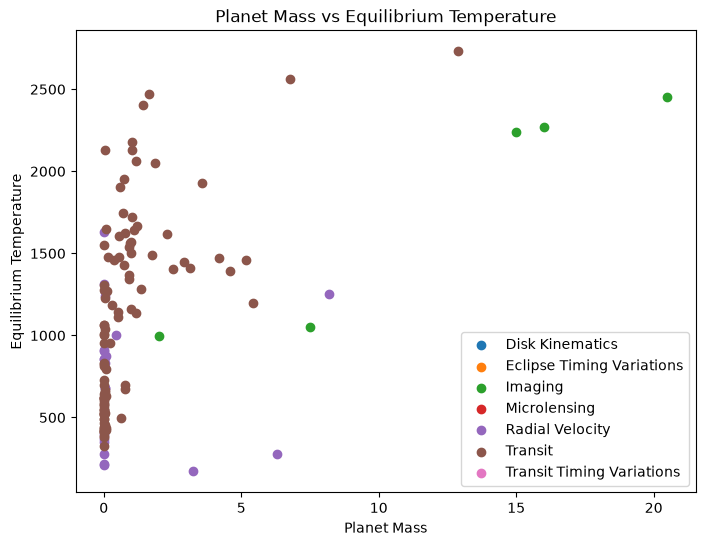

In [32]:
plt.figure(figsize=(8,6))

for method, group in df.groupby('discoverymethod'):
    plt.scatter(group['pl_bmassj'],
                group['pl_eqt'],
                label = method)
plt.xlabel("Planet Mass")
plt.ylabel("Equilibrium Temperature")
plt.title("Planet Mass vs Equilibrium Temperature")
plt.legend()
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

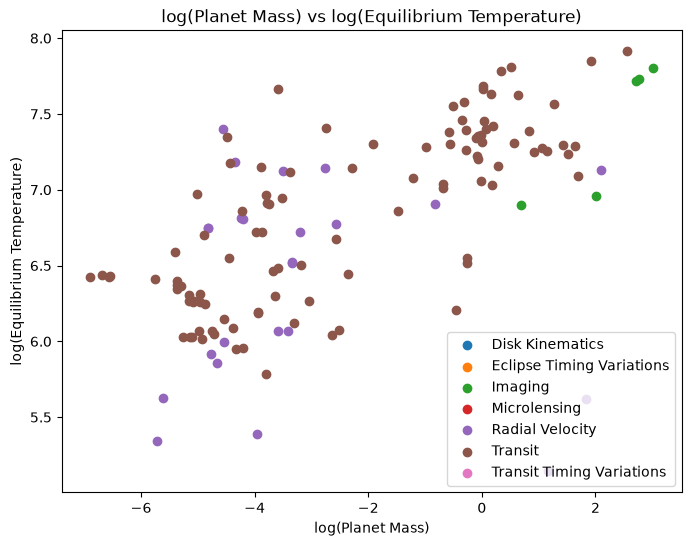

In [33]:
plt.figure(figsize=(8,6))

for method, group in df.groupby('discoverymethod'):
    plt.scatter(np.log(group['pl_bmassj']),
                np.log(group['pl_eqt']),
                label = method)
plt.xlabel("log(Planet Mass)")
plt.ylabel("log(Equilibrium Temperature)")
plt.title("log(Planet Mass) vs log(Equilibrium Temperature)")
plt.legend()
plt.show

In [34]:
# exoplanets found by the imaging method are more likely to be massive (see green points)

In [39]:
massive = new_df[new_df['pl_bmassj'] > 5]
coldest = massive.loc[massive['pl_eqt'].idxmin()]
print(coldest)

pl_name                eps Ind A b
hostname                 eps Ind A
discoverymethod    Radial Velocity
st_spectype                   K5 V
pl_eqt                       275.0
pl_bmassj                     6.31
Name: 597, dtype: object


Name: eps Ind A b
Index: 597
K: 275.0 K
Jupiter Masses: 6.31
Host Star: K5 V, not similar to sun

<function matplotlib.pyplot.show(close=None, block=None)>

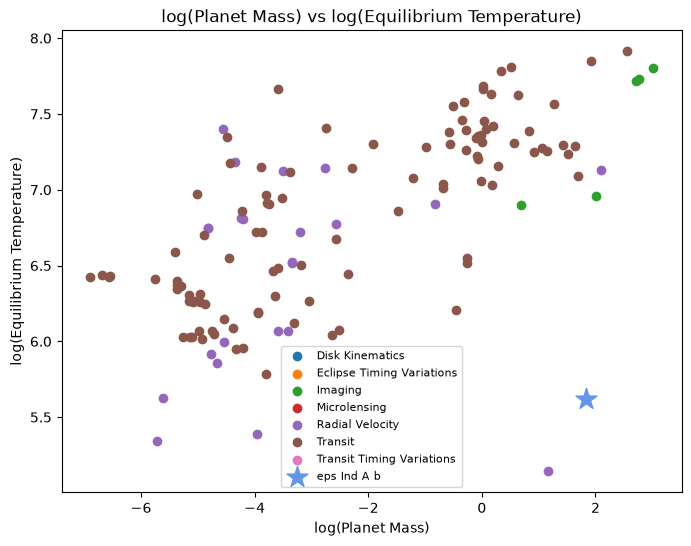

In [47]:
plt.figure(figsize=(8,6))

for method, group in df.groupby('discoverymethod'):
    plt.scatter(np.log(group['pl_bmassj']),
                np.log(group['pl_eqt']),
                label = method)
plt.scatter(np.log(coldest['pl_bmassj']),
            np.log(coldest['pl_eqt']),
            color = "cornflowerblue",
            marker = "*",
            s = 250,
            label = "eps Ind A b")

plt.xlabel("log(Planet Mass)")
plt.ylabel("log(Equilibrium Temperature)")
plt.title("log(Planet Mass) vs log(Equilibrium Temperature)")
plt.legend(fontsize = 8)
plt.show

## Check Your Answer

Title: A temperate super-Jupiter imaged with JWST in the mid-infrared
Abstract Summary: JWST photographed a giant exoplanet orbiting epsilon Indi A. The exoplanet in question is much cooler than most directly imaged ones, and has unusual concentrations of elements in the atmosphere. significant in the ability of JWST in detecting older/colder exoplanets
Match: Yes
Special: It is old and cool, unlike the other exoplanets found with direct imaging